## OLCI Sargassum Detection
`Apply the saved logistic regression to a full Level-1 scene and compare with SGI >= -2`

### 1. Import Libraries

In [1]:
import os

import numpy as np
import xarray as xr
import joblib
from scipy.ndimage import binary_dilation

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ignore warnings
import warnings
warnings.filterwarnings('ignore')

### 2. Define inputs and processing parameters

In [2]:
scene_dir  = 'S3A_OL_1_EFR____20240602T125835_20240602T130135_20240920T174426_0179_113_095_2880_MAR_R_NT_004.SEN3'
model_path = 'sargassum_logreg.joblib'
out_path   = 'sargassum_out_predic.nc'

# same masking as 0_OLCI3_zarrs_S3bucket_FR
buffer_pixels   = 20
cloud_flag_vars = ('saturated', 'partially_saturated', 'invalid')
land_flag_vars  = ('land', 'coastline', 'fresh_inland_water', 'tidal_region')
threshold       = -2

# Oa08 and Oa17 are needed for AFAI only
radbands = ('Oa08_radiance', 'Oa09_radiance', 'Oa12_radiance', 'Oa16_radiance', 'Oa17_radiance')

### 3. Load the model

In [3]:
saved = joblib.load(model_path)
model = saved['model']
print(saved['feature_cols'])

['SGI', 'AFAI']


### 4. Build the land and cloud masks

In [4]:
FLAG_file  = xr.open_dataset(os.path.join(scene_dir, 'qualityFlags.nc'), mask_and_scale = False)
flag_names = FLAG_file['quality_flags'].flag_meanings.split(' ')
flag_vals  = FLAG_file['quality_flags'].flag_masks
FLAGS      = FLAG_file['quality_flags'].values

# land mask: bitwise OR of the requested flag bits, buffered by buffer_pixels
land_flag_bits = np.uint64()
for flag in land_flag_vars:
    try:
        land_flag_bits = land_flag_bits | flag_vals[flag_names.index(flag)]
    except ValueError:
        print(flag + " not present")
land_mask_raw = (FLAGS & land_flag_bits) > 0
land_mask_buffered = binary_dilation(land_mask_raw, structure = np.ones((3, 3)), iterations = buffer_pixels)

# cloud mask: same bitwise approach, different flag set
cloud_flag_bits = np.uint64()
for flag in cloud_flag_vars:
    try:
        cloud_flag_bits = cloud_flag_bits | flag_vals[flag_names.index(flag)]
    except ValueError:
        print(flag + " not present")
cloud_mask_raw = (FLAGS & cloud_flag_bits) > 0

flag_mask = land_mask_buffered | cloud_mask_raw
print(f"Masked {flag_mask.sum()} of {flag_mask.size} pixels")

Masked 5647042 of 19897850 pixels


### 5. Load radiances and compute SGI and AFAI

Same expressions as the SNAP band maths used for the pin exports.

In [5]:
radiances = {}
for band in radbands:
    radiances[band] = xr.open_dataset(os.path.join(scene_dir, f'{band}.nc'))[band].values

band08 = radiances['Oa08_radiance']
band09 = radiances['Oa09_radiance']
band12 = radiances['Oa12_radiance']
band16 = radiances['Oa16_radiance']
band17 = radiances['Oa17_radiance']

SGI  = (band12 - band09) + (band16 - band09)
AFAI = band12 - (band08 + (band17 - band08) * 0.44)

# order must match feature_cols: SGI, AFAI
features = np.stack([SGI, AFAI], axis = -1)
del radiances, band08, band17

### 6. Predict on unmasked pixels

In [6]:
valid = np.all(np.isfinite(features), axis = -1) & ~flag_mask

prob = np.full(SGI.shape, np.nan, dtype = np.float32)
prob[valid] = model.predict_proba(features[valid])[:, 1]
del features

# -1 marks masked or invalid pixels
model_pred = np.where(valid, (prob >= 0.5).astype(np.int8), -1)
sgi_pred   = np.where(valid, (SGI >= threshold).astype(np.int8), -1)

both       = (model_pred == 1) & (sgi_pred == 1)
model_only = (model_pred == 1) & (sgi_pred == 0)
sgi_only   = (model_pred == 0) & (sgi_pred == 1)
print(f"Unmasked pixels: {valid.sum()}")
print(f"Both: {both.sum()}, model only: {model_only.sum()}, SGI >= {threshold} only: {sgi_only.sum()}")

Unmasked pixels: 14250808
Both: 1025, model only: 919, SGI >= -2 only: 6


### 7. Save the predictions

In [7]:
geo = xr.open_dataset(os.path.join(scene_dir, 'geo_coordinates.nc'))
lat = geo['latitude'].values
lon = geo['longitude'].values

ds_out = xr.Dataset(
    {'sargassum_prob' : (('rows', 'columns'), prob),
     'model_pred'     : (('rows', 'columns'), model_pred),
     'sgi_pred'       : (('rows', 'columns'), sgi_pred),
     'SGI'            : (('rows', 'columns'), np.where(valid, SGI, np.nan).astype(np.float32)),
     'flag_mask'      : (('rows', 'columns'), flag_mask.astype(np.int8)),
     'latitude'       : (('rows', 'columns'), lat.astype(np.float32)),
     'longitude'      : (('rows', 'columns'), lon.astype(np.float32))},
    attrs = {
        'source_product' : os.path.basename(scene_dir),
        'model'          : model_path,
        'features'       : ','.join(saved['feature_cols']),
        'buffer_pixels'  : buffer_pixels,
        'cloud_flags'    : ','.join(cloud_flag_vars),
        'land_flags'     : ','.join(land_flag_vars),
        'sgi_threshold'  : threshold})
ds_out.to_netcdf(out_path, encoding = {v: {'zlib': True, 'complevel': 4} for v in ds_out.data_vars})
print(f"Wrote {out_path}")

Wrote sargassum_out_predic.nc


### 8. Map the probability and the disagreement with SGI

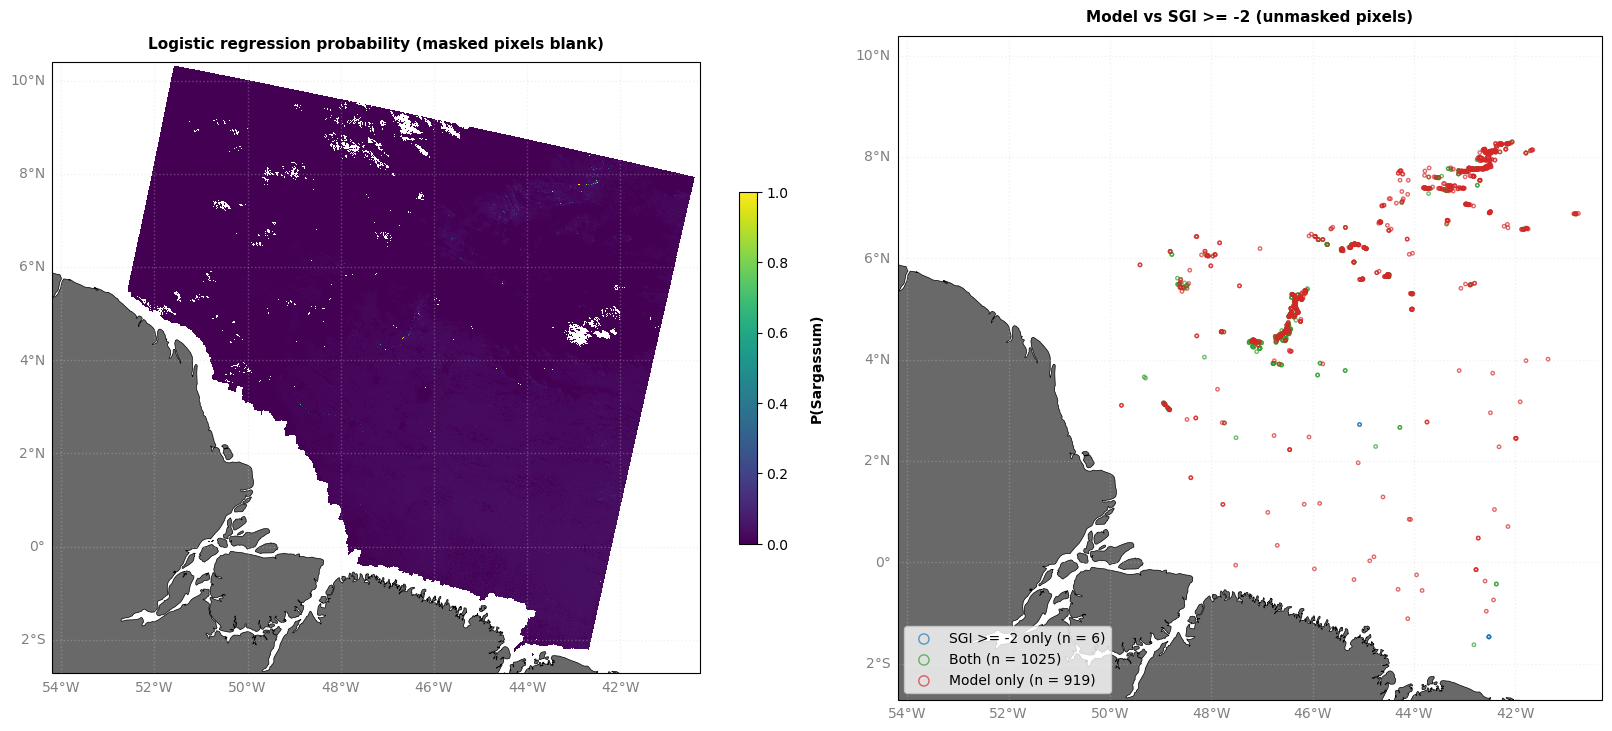

In [8]:
data_projection = ccrs.PlateCarree()
extent = [np.nanmin(lon), np.nanmax(lon), np.nanmin(lat), np.nanmax(lat)]

# subsample for plotting only
s = 4

fig, axs = plt.subplots(1, 2, figsize = (20, 10), subplot_kw = dict(projection = data_projection))

# --- Shared settings for both sub-plots ---
for ax in axs:
    ax.set_extent(extent, crs = data_projection)
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                                edgecolor = 'black', facecolor = 'dimgrey'))
    gl = ax.gridlines(crs = data_projection, draw_labels = True, linewidth = 1,
                      color = 'lightgray', alpha = 0.3, linestyle = ':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'grey'}
    gl.ylabel_style = {'size': 10, 'color': 'grey'}
# ---------------------------------------------------------------------------

im = axs[0].pcolormesh(lon[::s, ::s], lat[::s, ::s], prob[::s, ::s], cmap = plt.cm.viridis, transform = data_projection)
im.set_clim(0, 1)
cbar = plt.colorbar(im, ax = axs[0], orientation = "vertical", fraction = 0.025, pad = 0.055)
cbar.set_label("\nP(Sargassum)", fontsize = 10, weight = 'bold')
axs[0].set_title('Logistic regression probability (masked pixels blank)', fontsize = 11, weight = 'bold', pad = 10)

for mask, colour, name in [(sgi_only, 'tab:blue', f'SGI >= {threshold} only'),
                           (both, 'tab:green', 'Both'),
                           (model_only, 'tab:red', 'Model only')]:
    axs[1].scatter(lon[mask], lat[mask], marker = 'o', facecolor = 'none', edgecolor = colour,
                   s = 6, alpha = 0.7, transform = data_projection, label = f'{name} (n = {mask.sum()})')
axs[1].legend(loc = 'lower left', markerscale = 3)
axs[1].set_title(f'Model vs SGI >= {threshold} (unmasked pixels)', fontsize = 11, weight = 'bold', pad = 10)

plt.show()

In [9]:
import pandas as pd

sgi_floor   = -3
export_path = out_path.replace('.nc', f'_model_sgi_gt{abs(sgi_floor)}.txt')

# model-flagged pixels above the conservative SGI floor
export_mask = (model_pred == 1) & (SGI > sgi_floor)

rows, cols = np.nonzero(export_mask)
df_export = pd.DataFrame({
    'Name'   : [f'pix_{i + 1}' for i in range(len(rows))],
    'X'      : cols + 0.5,
    'Y'      : rows + 0.5,
    'Lon'    : lon[rows, cols],
    'Lat'    : lat[rows, cols],
    'SGI'    : SGI[rows, cols],
    'AFAI'   : AFAI[rows, cols],
    'prob'   : prob[rows, cols],
    'source' : np.where(both[rows, cols], 'both', 'model_only')})

df_export.to_csv(export_path, sep = '\t', index = False)
print(f"Wrote {len(df_export)} pixels to {export_path}")
df_export['source'].value_counts()

Wrote 1191 pixels to sargassum_out_predic_model_sgi_gt3.txt


source
both          1025
model_only     166
Name: count, dtype: int64